# Lab: MLP for a real biological classification problem

**BINF 6210/8210 - Machine Learning for Bioinformatics**
___

**Objectives:**
- prevent leakage
- compare logistic regression and MLP
- evaluate held-out ROC/PR and confusion matrices
- explore architecture and regularization
- interpret limitations
- use only training data for tuning
- inspect the test set once at the end.

**Dataset:**
- scikit-learn's Wisconsin Diagnostic Breast Cancer dataset (real measured features derived from digitized cell-nucleus images; **not gene expression**). It has 30 quantitative features and benign/malignant labels. This is an educational benchmark, not a clinical decision system.



In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
SEED = 42

In [3]:
data = load_breast_cancer(as_frame=True)
X = data.data

# Positive class = malignant (original dataset label 0)
y = (data.target==0).astype(int)
print('Shape:',X.shape,'malignant fraction:',y.mean())
display(X.head())

Shape: (569, 30) malignant fraction: 0.37258347978910367


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 1. Hold-out test and preprocessing
The test set remains untouched throughout model selection. Scaling occurs *inside* each cross-validation training fold through the pipeline.

In [4]:
Xdev, Xtest, ydev, ytest = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
logreg = Pipeline([('scale', StandardScaler()), ('model', LogisticRegression(max_iter=3000))])
mlp = Pipeline([('scale', StandardScaler()), ('model', MLPClassifier(max_iter=1500, early_stopping=False, random_state=SEED))])
search = GridSearchCV(mlp,{'model__hidden_layer_sizes':[(8,),(16,),(16,8)],
                         'model__alpha':[.001,.1,1.],
                         'model__learning_rate_init':[.001]},
                    scoring='roc_auc', cv=cv, n_jobs=1, refit=True)
search.fit(Xdev,ydev)
logreg.fit(Xdev,ydev)

print('Best MLP CV ROC AUC:',round(search.best_score_,3))
print('Selected parameters:',search.best_params_)

Best MLP CV ROC AUC: 0.996
Selected parameters: {'model__alpha': 1.0, 'model__hidden_layer_sizes': (16,), 'model__learning_rate_init': 0.001}


## 2. Final held-out evaluation
ROC AUC measures ranking across thresholds; average precision summarizes the precision–recall curve. Report class prevalence as context. Threshold-dependent predictions below use 0.5.

Logistic accuracy 0.965 ROC AUC 0.996 average precision 0.994
MLP accuracy 0.991 ROC AUC 0.998 average precision 0.997


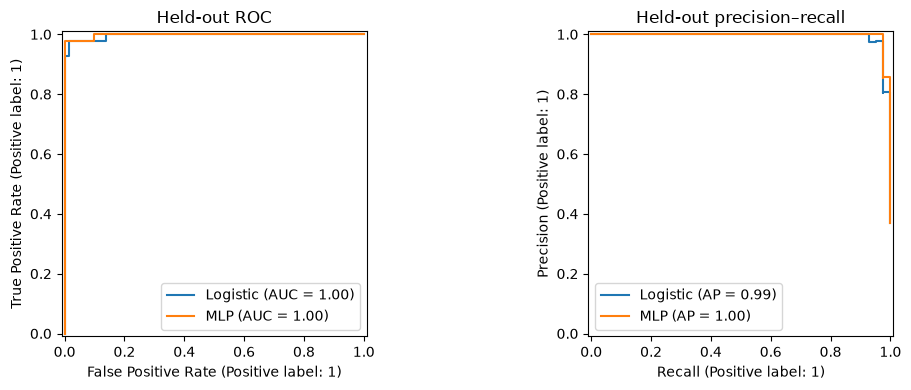

MLP classification report (malignant=1):
              precision    recall  f1-score   support

      benign       0.99      1.00      0.99        72
   malignant       1.00      0.98      0.99        42

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



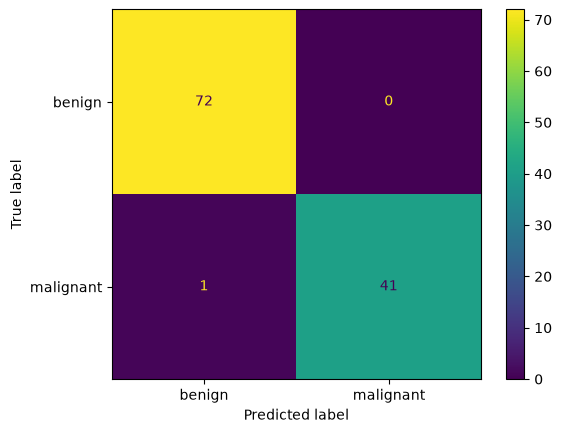

In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,est in [('Logistic',logreg),('MLP',search.best_estimator_)]:
    prob=est.predict_proba(Xtest)[:,1]
    pred=(prob>=.5).astype(int)
    print(name,'accuracy',round(accuracy_score(ytest,pred),3),
          'ROC AUC',round(roc_auc_score(ytest,prob),3),
          'average precision',round(average_precision_score(ytest,prob),3))
    RocCurveDisplay.from_predictions(ytest,prob,name=name,ax=axes[0])
    PrecisionRecallDisplay.from_predictions(ytest,prob,name=name,ax=axes[1])
axes[0].set_title('Held-out ROC');axes[1].set_title('Held-out precision–recall')
plt.tight_layout();plt.show()
print('MLP classification report (malignant=1):')
print(classification_report(ytest,search.best_estimator_.predict(Xtest),target_names=['benign','malignant']))
ConfusionMatrixDisplay.from_estimator(search.best_estimator_,Xtest,ytest,display_labels=['benign','malignant']);plt.show()

## 3. Inspect the trained MLP
`coefs_` contains one matrix per layer. The model has one sigmoid output for binary classification. Hidden-layer weights are not direct biological effect estimates.

Layer weight shapes: [(30, 16), (16, 1)]
Bias shapes: [(16,), (1,)]
Iterations: 461


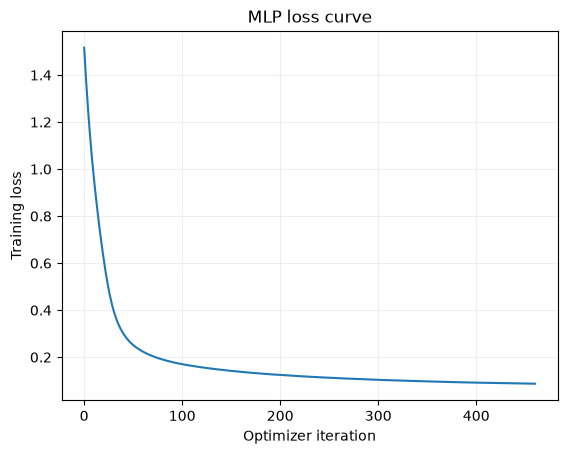

[array([[ 3.79804359e-03,  2.93445055e-02,  1.62339393e-01,
         8.96549593e-02, -3.30559787e-02,  2.16251060e-02,
        -1.48431564e-01,  9.44657430e-02,  5.67081816e-02,
        -3.62191767e-02, -1.54226115e-01,  1.75947010e-01,
         1.37772703e-01, -2.39517744e-02,  8.61775582e-02,
        -1.14487258e-01],
       [ 3.56145832e-03, -1.72744905e-01,  4.44492627e-02,
         5.43366316e-02,  5.48449717e-02,  2.26828808e-02,
        -3.03652905e-01,  9.10175902e-02,  2.97909432e-02,
        -6.98678208e-02, -7.38370440e-02,  2.23383637e-01,
         1.14487645e-01, -6.18823150e-02,  1.17618169e-01,
        -1.15782760e-01],
       [-9.00031185e-04,  3.08881873e-02,  2.35277089e-01,
         1.57725303e-01,  5.13281798e-03,  2.07518341e-02,
        -4.02941584e-03,  5.48999536e-02, -3.62325585e-02,
        -1.30281623e-01, -1.51561981e-01,  1.64688790e-01,
         3.32134381e-02,  8.39480535e-02,  8.94861736e-02,
        -7.13288403e-02],
       [ 3.98588095e-03, -3.37743973

In [8]:
fitted = search.best_estimator_.named_steps['model']
print('Layer weight shapes:',[w.shape for w in fitted.coefs_])
print('Bias shapes:',[b.shape for b in fitted.intercepts_])
print('Iterations:',fitted.n_iter_)
plt.plot(fitted.loss_curve_)
plt.xlabel('Optimizer iteration')
plt.ylabel('Training loss')
plt.title('MLP loss curve')
plt.grid(alpha=.2);plt.show()
print(fitted.coefs_)

## 4. Interpretation and critical reflection
**Questions:**
1. Which metric is most important if false negatives (missed malignancies) are costly? What trade-off arises when lowering the decision threshold?
2. Why does `StandardScaler` belong inside the pipeline rather than being fitted to the full dataset before cross-validation?
3. Compare the tuned MLP and logistic regression. Does extra complexity guarantee improvement?
4. Why might an MLP with thousands of genes but only dozens of samples overfit?
5. What additional evidence would be required before clinical use (external cohorts, calibration, subgroup performance, prospective validation)?